# Customer Segmentation with Clustering
**Goal:** segment a set of wholesale customers into groups using k-means, decide how many
groups with the **elbow method** and the **silhouette score**, and explain what each segment is.



## Your dataset

Use the **Wholesale Customers** dataset: annual spending (monetary units) by 440 clients of a
wholesale distributor across product categories.

- Download: [UCI Wholesale Customers](https://archive.ics.uci.edu/dataset/292/wholesale+customers) (also searchable as "Wholesale customers" on Kaggle).
- Columns: `Channel`, `Region` (these are labels, not spending), then the six spend columns `Fresh`, `Milk`, `Grocery`, `Frozen`, `Detergents_Paper`, `Delicassen`.
- Cluster on the **six spend columns**. `Channel` and `Region` are context only; do not cluster on them.

In [2]:
# Step 0: imports (given - just run this)
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
#from google.colab import drive

import os
os.environ["MKL_THREADING_LAYER"] = "GNU"

ETSU_NAVY = "#00053E"
ETSU_GOLD = "#FFC72C"
print("Ready.")


Ready.


## Step 1: Load the data

Change the path to the real Wholesale file when you have it.

In [3]:
#drive.mount('/content/drive')

In [4]:
# GIVEN: load the data
#df = pd.read_csv("/content/drive/MyDrive/wholesale_sample.csv")
df = pd.read_csv("wholesale_sample.csv")

spend_cols = ["Fresh", "Milk", "Grocery", "Frozen", "Detergents_Paper", "Delicassen"]
df.head()

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,1,1,4181,10024,26577,1979,9194,1151
1,2,3,3346,4848,14310,1155,2666,1768
2,2,3,3687,8096,10837,870,7701,1345
3,1,2,3008,6327,16926,1032,5303,1582
4,2,3,4704,13163,20537,1507,3073,1267


## Step 2: Explore

Look at the data before clustering: size, column types, and the ranges of the spend columns
(the ranges tell you whether scaling is needed).

In [5]:
# TODO: explore the data
# Hint: df.shape, df.info(), and df[spend_cols].describe()
df.shape 
df.info()
df[spend_cols].describe()



<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Channel           150 non-null    int64
 1   Region            150 non-null    int64
 2   Fresh             150 non-null    int64
 3   Milk              150 non-null    int64
 4   Grocery           150 non-null    int64
 5   Frozen            150 non-null    int64
 6   Detergents_Paper  150 non-null    int64
 7   Delicassen        150 non-null    int64
dtypes: int64(8)
memory usage: 9.5 KB


,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
count,150.000000,150.000000,150.000000,150.000000,150.000000,150.000000
mean,10298.826667,5422.726667,7938.353333,3017.386667,2981.926667,1808.906667
std,8398.147983,3820.906314,7053.621991,1977.922844,2879.237096,950.893154
min,2043.000000,1313.000000,1451.000000,760.000000,318.000000,483.000000
25%,3923.250000,2524.250000,2877.750000,1461.500000,871.750000,1154.500000
50%,5748.500000,3740.000000,4497.500000,2113.000000,1370.500000,1581.000000
75%,17153.250000,8001.500000,12043.250000,4271.750000,5148.750000,2161.500000
max,35404.000000,18274.000000,34411.000000,8236.000000,12186.000000,5332.000000


## Step 3: Select features and scale

k-means uses distance, and these spend columns are on very different scales, so scale them.

- Build X from the six spend columns.
- Scale with StandardScaler.

In [6]:
# TODO: build X from the spend columns and scale it
# Hint: X = df[spend_cols].values
# Hint: Xs = StandardScaler().fit_transform(X)

X = df[spend_cols].values
Xs = StandardScaler().fit_transform(X)



## Step 4: Choose the number of clusters (elbow + silhouette)

Try a range of k (say 2 to 10). For each k, fit k-means and record two things:

- `kmeans.inertia_` for the **elbow** plot (tightness; look for where the curve bends),
- `silhouette_score(Xs, labels)` for the **silhouette** plot (separation; higher is better).

Plot both, then pick a k and justify it in a sentence.

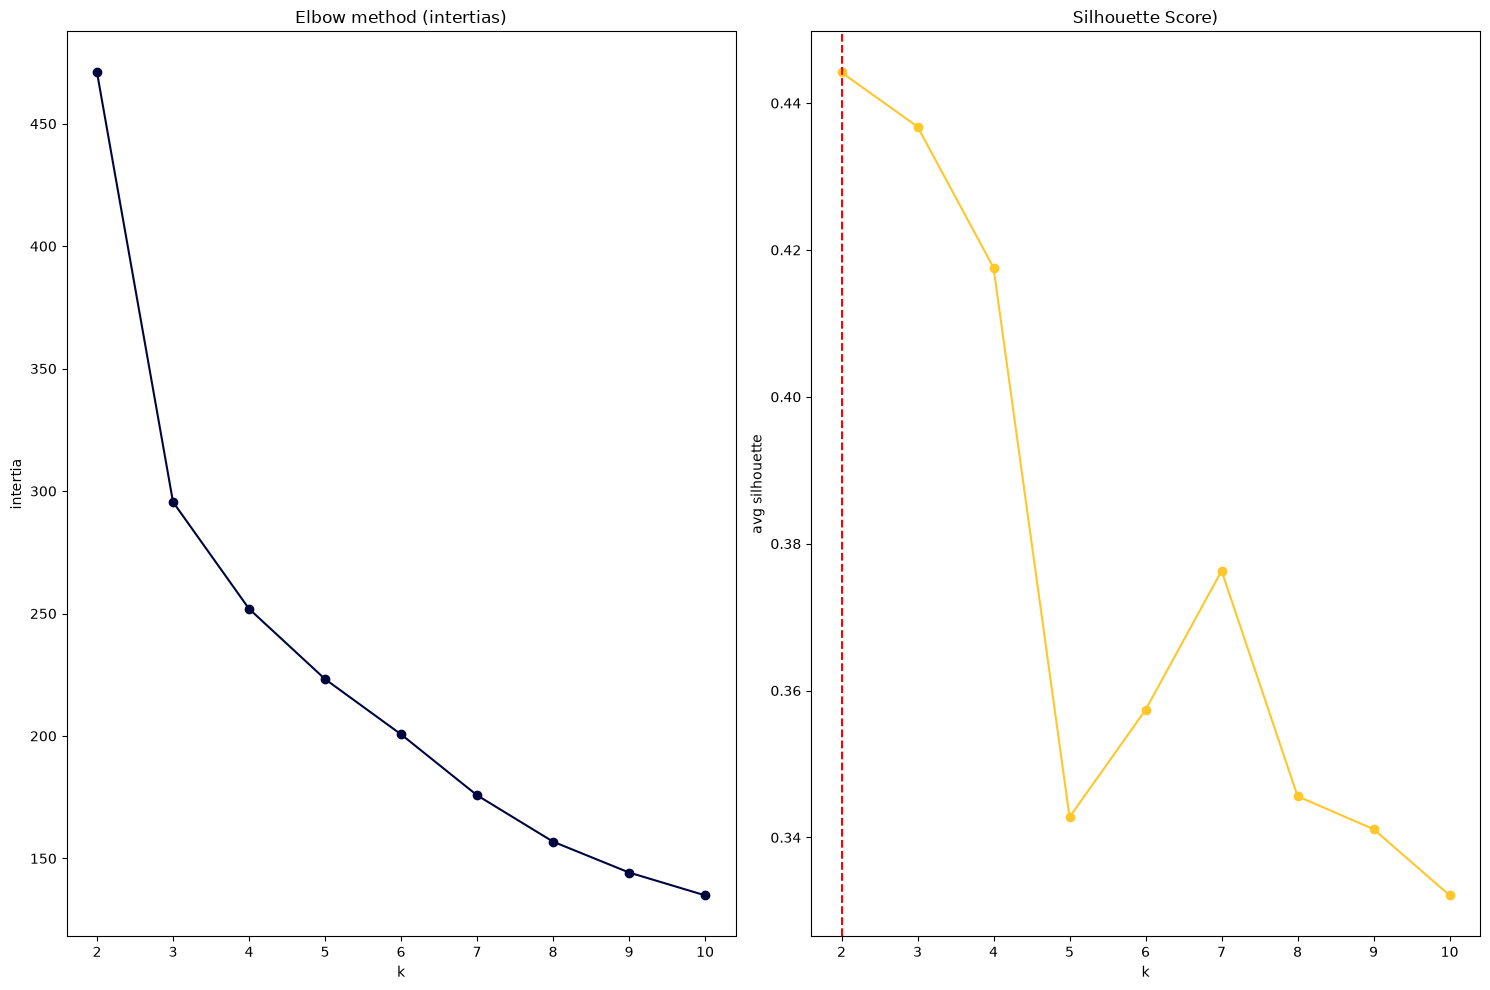

In [23]:
# TODO: loop over k, collect inertia and silhouette, then plot both
# Hint:
# ks = range(2, 11)
# inertias, sils = [], []
# for k in ks:
#     km = KMeans(n_clusters=k, random_state=42, n_init=10).fit(Xs)
#     inertias.append(km.inertia_)
#     sils.append(silhouette_score(Xs, km.labels_))
# then make two plots: ks vs inertias, and ks vs sils

ks = range(2, 11)
inertias, sils = [], []
for k in ks:
    km = KMeans(n_clusters=k, random_state=42, n_init=10).fit(Xs)
    inertias.append(km.inertia_)
    sils.append(silhouette_score(Xs, km.labels_))

fig, ax = plt.subplots(1, 2, figsize =(15, 10))
ax[0].plot(list(ks), inertias, "o-", color=ETSU_NAVY)
ax[0].set_title("Elbow method (intertias)"); ax[0].set_xlabel("k"); ax[0].set_ylabel("intertia")

ax[1].plot(list(ks), sils, "o-", color=ETSU_GOLD)
ax[1].set_title("Silhouette Score)"); ax[1].set_xlabel("k"); ax[1].set_ylabel("avg silhouette")

best_k = list(ks)[int(np.argmax(sils))] 
ax[1].axvline(best_k, color="red",linestyle = "--")
plt.tight_layout();
plt.show();


**Your chosen k and why:**

I chose two as my k value because of what the silhouette score line graph showed. Two is large enough to not merge groups and loose grainularity but small enough to avoid noisy data.


## Step 5: Fit k-means with your chosen k

In [15]:
# TODO: fit KMeans at your chosen k and attach the labels to df
# Hint: kmeans = KMeans(n_clusters=YOUR_K, random_state=42, n_init=10).fit(Xs)
# Hint: df["cluster"] = kmeans.labels_

kmeans = KMeans(n_clusters=2, random_state=42, n_init=10).fit(Xs)
df["cluster"] = kmeans.labels_


## Step 6: Visualize the clusters with PCA

You have six features, so you cannot plot them directly. Reduce the scaled data to 2D with PCA
and color the points by cluster.

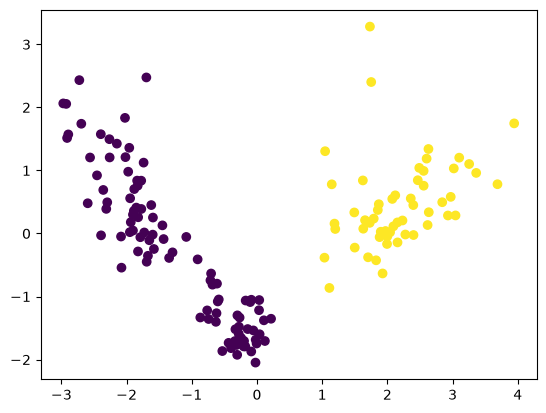

In [26]:
# TODO: project Xs to 2D with PCA and scatter it, colored by df["cluster"]
# Hint: pcs = PCA(n_components=2).fit_transform(Xs)
# Hint: plt.scatter(pcs[:,0], pcs[:,1], c=df["cluster"])

pcs = PCA(n_components=2).fit_transform(Xs)
plt.scatter(pcs[:,0], pcs[:,1], c=df["cluster"])


## Step 7: Profile and interpret the segments

Summarize each cluster by the average of each spend column (and how many customers are in it),
then describe each segment in plain words.

In [29]:
# TODO: build a profile table of per-cluster averages
# Hint: df.groupby("cluster")[spend_cols].mean().round(0)
# Hint: df["cluster"].value_counts() for the sizes
df.groupby("cluster")[spend_cols].mean().round(0)





,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
cluster,,,,,,
0,13872.0,2996.0,3373.0,3870.0,1055.0,1895.0
1,4128.0,9614.0,15824.0,1545.0,6310.0,1660.0


## Step 8: Findings

1. **How many clusters did you choose, and why?** (what the elbow and silhouette showed)

I chose two because that is what the silhouette score plot showed as being the most apropriate. Most likely because it is large enough to not merge groups and loose grainularity but small enough to avoid noisy data.

2. **Describe each segment** in plain language. What kind of customer is it (for example, a grocery-heavy retailer vs a fresh-and-frozen restaurant supplier)?

Segment 0 seems to be more of a fresh and frozen while segment 1 seems to be a more grocery-heavy retailer

3. **One action per segment:** what should the distributor do differently for each group?

The distrubutor should focus more on the quality of "fresh" items and maybe increase the variety for segment 0 as well, while for segment 1 should be more grocery and milk focused.

4. **One limitation:** what would you want to check or try next (different k, more features, outliers)?

I would want to check a different k value just to see what would happen, and I would like to exlude some of the various outliers in the data (specifically the three for segment 1)

## Submission checklist

- This notebook, renamed `Lastnames_Clustering.ipynb`, all cells run with output showing